# 13 Caching
A search takes about 10 ms. When the same question comes again, there is no need to search again: the service can keep the answer and give it back. That is a **cache**. Here I add one to the service, show how it works, and measure what it saves. Nothing here uses the 20 locked final products.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)  # the project reads data/archive.zip relative to the project folder
plt.rcParams.update(
    {"figure.figsize": (9, 3.4), "axes.spines.top": False, "axes.spines.right": False}
)
pd.set_option("display.width", 200)

data = json.loads((root / "results" / "cache_benchmark.json").read_text(encoding="utf-8"))
print("loaded the saved results")

loaded the saved results


## 1. How my cache works
| Part | What it does |
|---|---|
| Where it lives | Inside the service, in its memory (an **in-process** cache). Nothing else to install or run |
| What is saved | The answer to one question: the product and the number of results. A different product or a different number is a different question. (The mode and the weights will be part of the question when the API gets them.) An old ID and the product that was kept share one entry |
| Size | 1,024 answers by default. When it is full, the answer that was used least recently is dropped (least recently used). `PS_CACHE_SIZE=0` turns the cache off |
| Which answers | Only answers of up to 100 results, so that a few huge answers cannot fill the memory. A product that does not exist is never saved |
| Many requests at once | It is safe: a lock protects it |
| What the API shows | The plain endpoint has an `X-Cache` header (`hit` or `miss`), the details endpoint has a `cached` field, and `GET /cache` reports the entries, the hits, the misses and the hit rate |
| When it is empty again | When the service restarts. There is no expiry, because the data does not change |

The code is `src/product_similarity/cache.py` and the part in `src/product_similarity/api.py`.

### What the API shows
The cache adds three things to the API. They are also checked in the CI on every push (`.github/workflows/ci.yml`).

| Where | New | Checked in CI |
|---|---|---|
| `GET /find_similar_products` | The header `X-Cache`, `hit` or `miss` | The same question asked again must say `hit` |
| `GET /find_similar_products/details` | The field `cached`, `true` or `false` | The repeated question must have `cached: true` |
| `GET /cache` (a new endpoint) | The statistics: entries, hits, misses and the hit rate | It must report the cache enabled, with at least one hit and one entry |

Here they are on a real request, asked three times:

In [2]:
from fastapi.testclient import TestClient

from product_similarity.api import create_app
from product_similarity.service import build_final_engine

engine = build_final_engine("exact")
question = {"product_id": "26d41bdc1495de290bc8e6062d927729", "num_similar": 5}
with TestClient(create_app(lambda: engine)) as client:
    plain = client.get("/find_similar_products", params=question)
    print("plain endpoint, first time: X-Cache =", plain.headers["X-Cache"])
    plain = client.get("/find_similar_products", params=question)
    print("plain endpoint, second time: X-Cache =", plain.headers["X-Cache"])
    details = client.get("/find_similar_products/details", params=question).json()
    print(
        f"details endpoint: cached = {details['cached']}, response time = {details['response_time_ms']} ms"
    )
    print("GET /cache:", client.get("/cache").json())

plain endpoint, first time: X-Cache = miss
plain endpoint, second time: X-Cache = hit
details endpoint: cached = True, response time = 0.02 ms
GET /cache: {'enabled': True, 'max_entries': 1024, 'entries': 1, 'hits': 2, 'misses': 1, 'hit_rate': 0.6667}


## 2. One request: a miss against a hit
The same rule as in the other notebooks: 200 random products (seed 2020, never a locked product). For each product the cache is emptied, then the same question is asked twice. The first request is a miss (the search runs) and the second is a hit. Five rounds, the fastest kept, the median of the 200. The time is the whole request through the service, including the web part, so a hit is not zero.

In [3]:
pair = data["miss_against_hit"]
display(
    pd.DataFrame(
        {
            "median (ms)": [pair["miss_median_ms"], pair["hit_median_ms"]],
            "95th percentile (ms)": [
                pair["miss_95th_percentile_ms"],
                pair["hit_95th_percentile_ms"],
            ],
        },
        index=["not in the cache (miss)", "in the cache (hit)"],
    )
)
print(
    f"a hit is about {pair['times_faster']} times faster; one cached answer of 10 results takes about {data['memory_kb_per_cached_answer']} KB"
)

,median (ms),95th percentile (ms)
not in the cache (miss),9.586,10.528
in the cache (hit),0.767,0.785


a hit is about 12.5 times faster; one cached answer of 10 results takes about 1.82 KB


### What this shows
A request that is in the cache takes 0.77 ms against 9.6 ms for a new search, about 12 times faster. A hit does no search, so the 0.77 ms is the web part of the request; the service's own timer (`response_time_ms`, as in the demo above) shows only about 0.02 ms for the work inside the service. One cached answer is small (about 1.8 KB), so even 1,024 answers take only about 2 MB.

## 3. Traffic where a few products are asked for often
A cache only helps when the same questions come again. I have no real traffic, so I simulate it: 2,000 requests drawn from all products, where the popularity of a product falls off like 1/rank (a few products are asked for very often, most hardly ever). This is an assumption, and the real result depends on the real traffic. Each cache size gets the same 2,000 requests.

,requests answered from the cache,average time per request (ms)
cache_size,,
0,0.0000,10.260
100,0.3210,7.205
1000,0.4945,5.548
5000,0.4945,5.545


different products asked for in the 2,000 requests: 1011


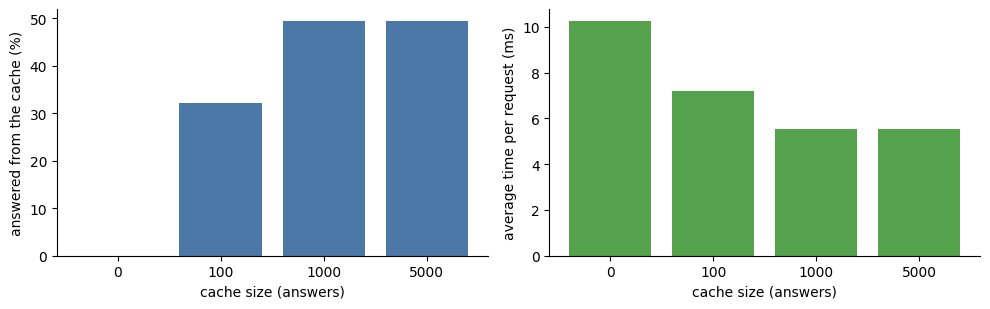

In [4]:
rows = pd.DataFrame(data["traffic_simulation"]["results"]).set_index("cache_size")
display(
    rows[["hit_rate", "average_ms_per_request"]].rename(
        columns={
            "hit_rate": "requests answered from the cache",
            "average_ms_per_request": "average time per request (ms)",
        }
    )
)
print(
    "different products asked for in the 2,000 requests:",
    int(rows["different_products_asked"].iloc[0]),
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(rows.index.astype(str), rows["hit_rate"] * 100, color="#4c78a8")
axes[0].set_xlabel("cache size (answers)")
axes[0].set_ylabel("answered from the cache (%)")
axes[1].bar(rows.index.astype(str), rows["average_ms_per_request"], color="#54a24b")
axes[1].set_xlabel("cache size (answers)")
axes[1].set_ylabel("average time per request (ms)")
plt.tight_layout()
plt.show()

### What this shows
Without a cache every request is a search (10.3 ms on average). A cache of 100 answers already answers about a third of the requests, and a cache of 1,000 answers about half, so the average time halves to 5.5 ms. A cache of 5,000 gives the same as 1,000, because only about 1,000 different products were asked for in these 2,000 requests. With traffic that never repeats, the cache would not help, and with traffic that repeats more, it would help more.

## 4. The trade-offs
- **It is lost when the service restarts.** Then it fills up again as requests come in. This costs only some speed, never a wrong answer.
- **Each copy of the service has its own cache.** On Kubernetes, with several pods, a request that reaches one pod does not profit from what another pod has saved, so fewer requests are hits. The answer is the same in every pod, because the search is the same.
- **Redis would be the next step.** Redis is a separate server that all the copies of the service can share, and its data stays when a service restarts. It costs one more service to run and a little time for the network. I did not build it, because one in-process cache is enough to show the effect, and the data does not change.

## 5. Recorded in MLflow
Each measurement is a run in the experiment `caching`: one request that is not in the cache, one that is, and the traffic simulation for each cache size (6 runs). Each run stores its settings, its time per request and its hit rate, and the JSON file as an attachment:

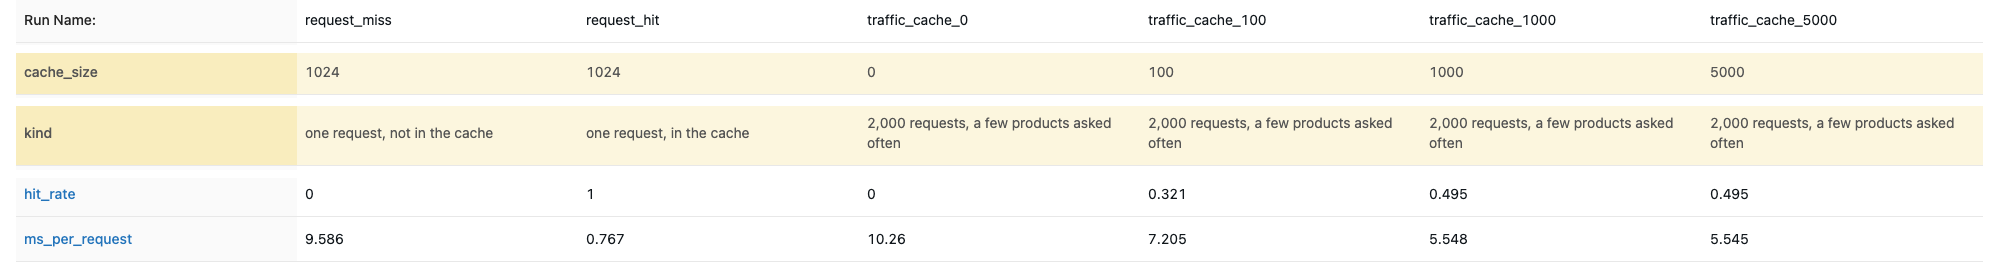

In [5]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_cache_runs.png", width=1000)

## 6. Conclusion

**What I did.** I added caching to the service. It remembers the answers to the last 1,024 questions, so a question that comes again is answered from memory, without searching.

| One request | Time |
|---|---|
| Not remembered (miss) | 9.6 ms |
| Remembered (hit) | 0.77 ms |

**What I found.** A remembered answer is about 12 times faster, and it is the same answer. In a simulation where a few products are asked for often, the cache answers about half of the requests, and the average time drops from 10.3 ms to 5.5 ms.

**Limitation.** The cache is lost when the service restarts. With several copies of the service (Kubernetes), each copy has its own cache, so fewer requests are answered from memory. A shared cache such as Redis would fix this. I did not build it.

**What I do next.** The stronger API, then Kubernetes and CI/CD, then the page, and at the end the 20 locked products.